# Grouping tumor solids by gene uniformity (e.g. POSTN)

How evenly does a gene surround each tumor solid? For every solid, the **distance-weighted uniformity** (10–100 µm,
30° sectors) of the chosen genes is computed; the solids are then grouped on these values.

- `scomv.solid_gene_uniformity(grid, solid, genes)` → solids × genes. With `size_factor=True` (default) each solid's
  expression amount is corrected by a median-of-ratios size factor, so that solids in dense stroma do not get higher
  uniformity for every gene.
- `scomv.cluster_solids(features)` → Gaussian mixture with the number of groups chosen by BIC (or
  `method="ward", n_clusters=k`). Several genes can be used together (z-scored).

## 1. Data, grid and solids

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import stlearn as st
import scomv
from scomv.preparation.skny_calc_distance import calculate_distance

adata = st.ReadXenium(
    feature_cell_matrix_file="../tutorial_data/xenium_data/cell_feature_matrix.h5",
    cell_summary_file="../tutorial_data/xenium_data/cells.csv.gz",
    library_id="example data", image_path=None, scale=1, spot_diameter_fullres=10,
)
sc.pp.filter_genes(adata, min_cells=300)

# 10 µm grid and SKNY tumor boundary (CDH1 / EPCAM)
N_COL = int((adata.obs.imagecol.max() - adata.obs.imagecol.min()) / 10)
N_ROW = int((adata.obs.imagerow.max() - adata.obs.imagerow.min()) / 10)
grid = st.tl.cci.grid(adata, n_row=N_ROW, n_col=N_COL, n_cpus=10, verbose=False)
grid = calculate_distance(grid, pos_marker_ls=["CDH1", "EPCAM"])
sc.pp.filter_cells(adata, min_genes=10)

[calculate_distance] N_ROW=547, N_COL=752, positive cells in grid=100012/411344


Calculating gene expression of (-∞, 0]


40 tumor solids


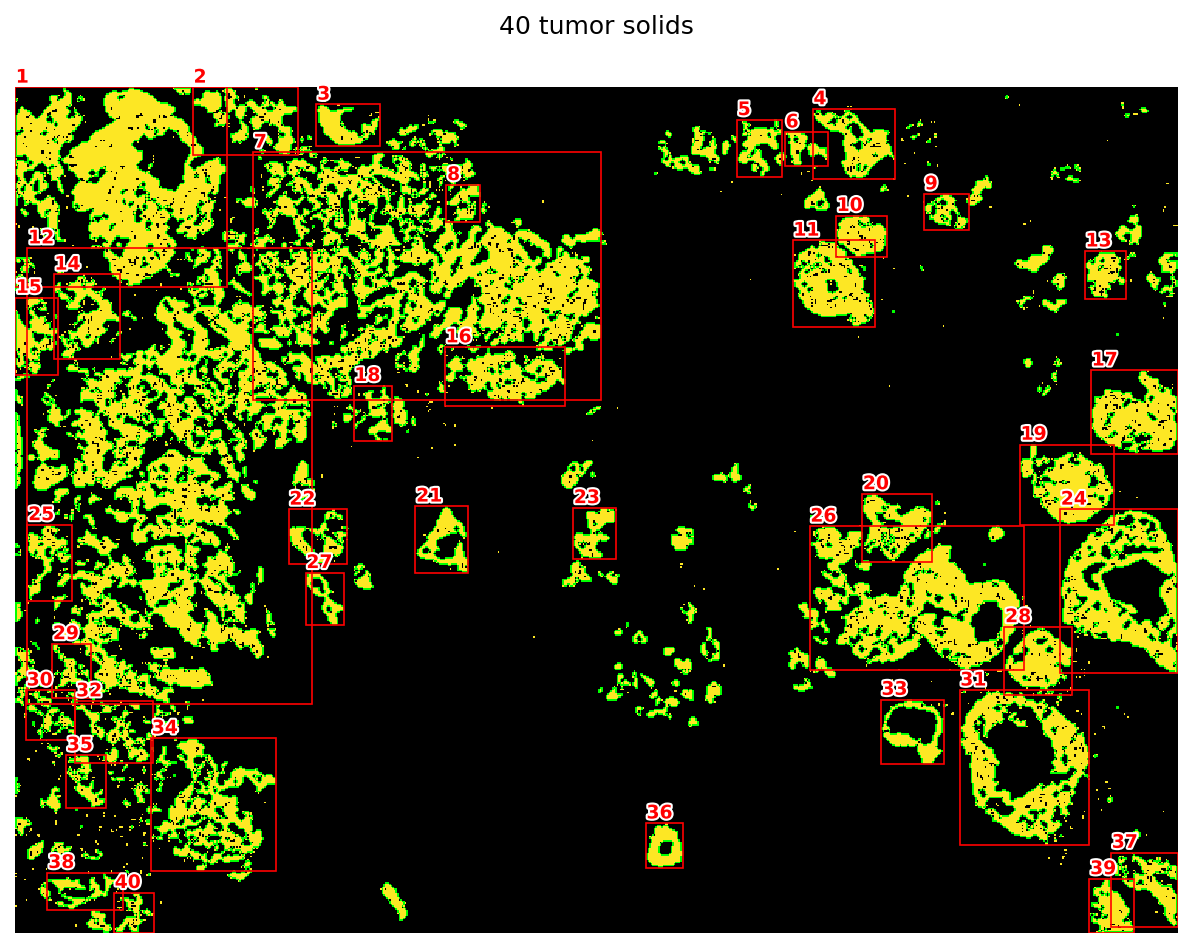

In [2]:
from scomv.tumor_solid import extract_tumor_solids, label_solid_regions, plot_tumor_solids, plot_cluster_map

MIN_AREA = 250   # minimum solid area (grid squares)
solid = extract_tumor_solids(grid, section_um=None, min_area=MIN_AREA)
labels_img, _, _ = label_solid_regions(grid, min_area=MIN_AREA)
print(f"{len(solid.obs)} tumor solids")
plot_tumor_solids(solid, title=f"{len(solid.obs)} tumor solids")
plt.show()

## 2. One gene: POSTN

In [3]:
postn_u = scomv.solid_gene_uniformity(grid, solid, ["POSTN"])
postn_groups = scomv.cluster_solids(postn_u, n_boot=100)     # k by BIC; bootstrap shows how stable that choice is
postn_groups.selection

uniformity of 1 gene(s) around 40 solids (size factor: median 0.93, range 0.31-13.33)


BIC choice: k = 1
       n_solids  mean POSTN
group                      
all          40       0.782


,BIC,bootstrap choice
1,-110.786410,39
2,-109.569399,28
3,-99.511064,7
4,-94.262087,9
5,-86.566136,6
6,-79.508317,11


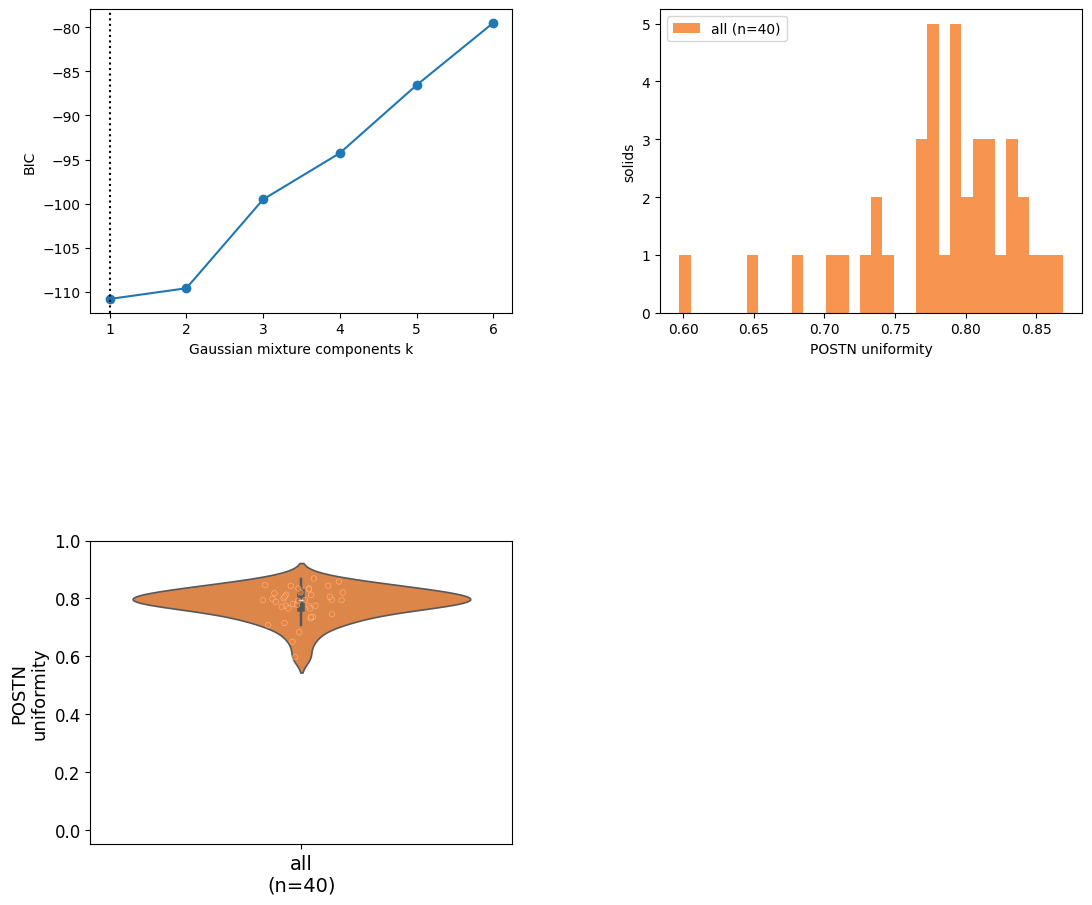

In [4]:
scomv.plot_solid_clusters(postn_groups)
plt.show()

BIC prefers a single group here; a fixed number of groups can be requested with `n_clusters`:

BIC choice: k = 1 (using k = 2)
       n_solids  mean POSTN
group                      
low           8       0.694
high         32       0.804


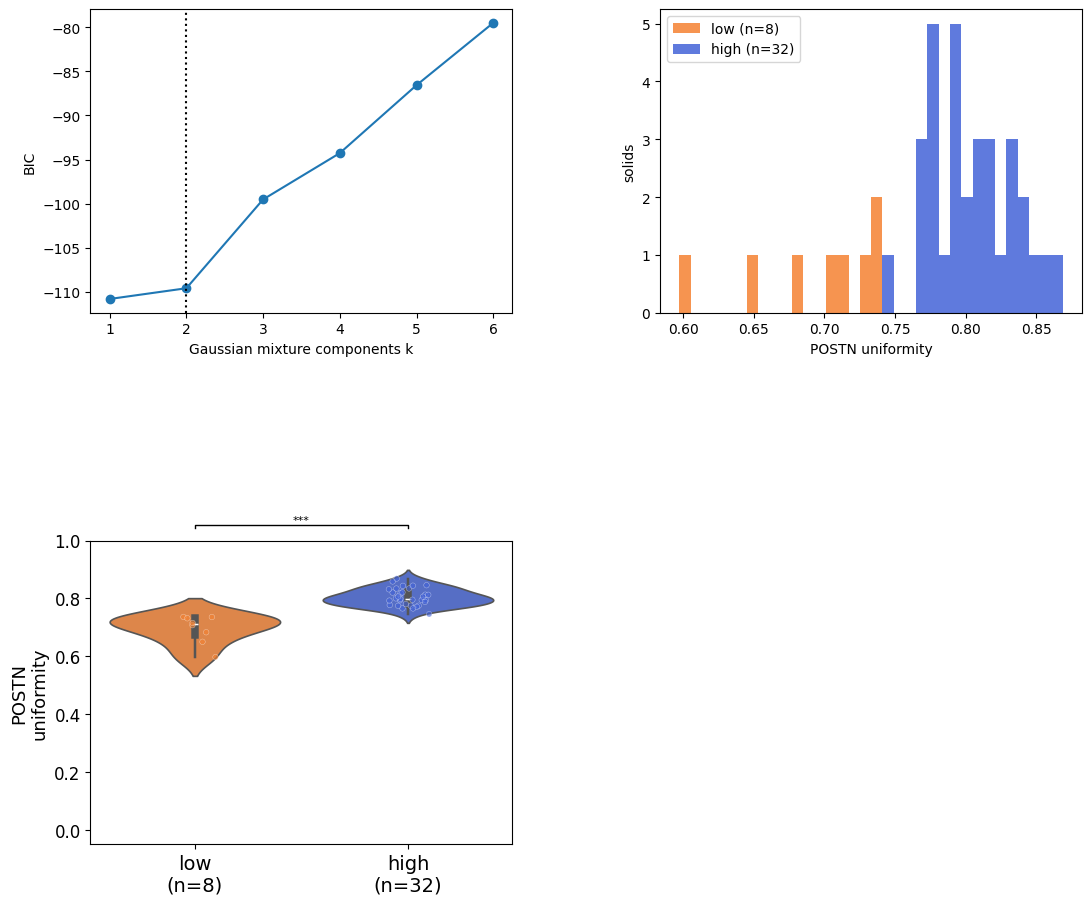

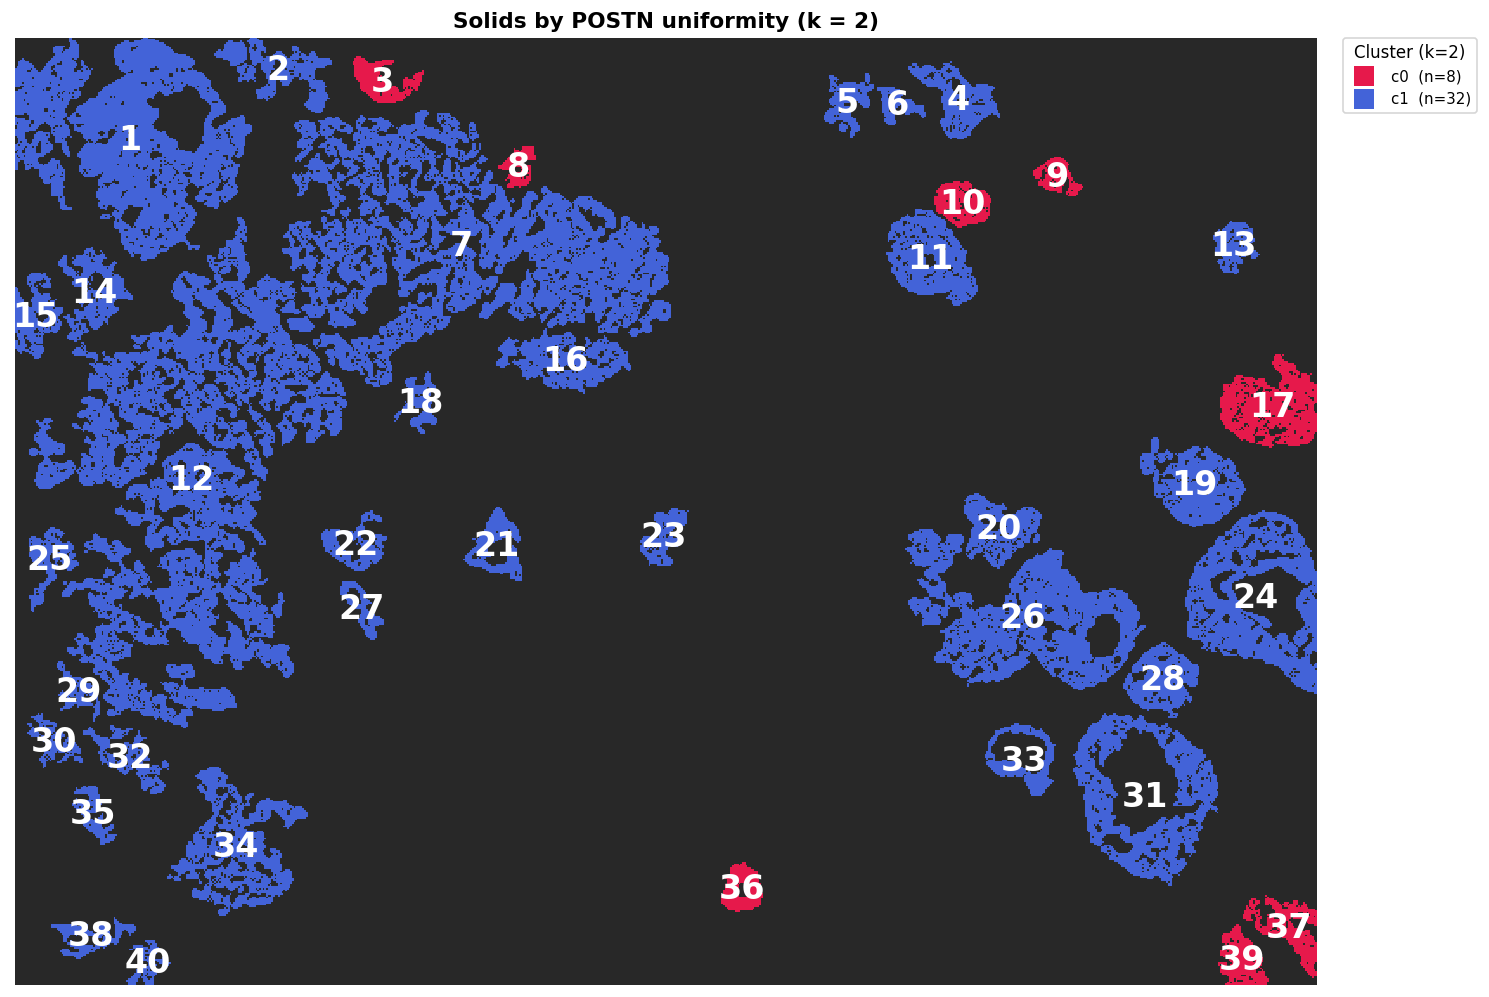

In [5]:
postn_2 = scomv.cluster_solids(postn_u, n_clusters=2)
scomv.plot_solid_clusters(postn_2)
plt.show()
plot_cluster_map(labels_img, solid.obs, postn_2.cluster_of_solid, n_clusters=postn_2.k,
                 title="Solids by POSTN uniformity (k = 2)")
plt.show()

## 3. Several genes

uniformity of 5 gene(s) around 40 solids (size factor: median 0.93, range 0.31-13.33)
       n_solids  mean POSTN  mean LUM  mean CD3E  mean PTPRC  mean CD68
group                                                                  
low           7       0.698     0.708      0.351       0.504      0.505
mid          21       0.801     0.813      0.454       0.582      0.594
high         12       0.800     0.839      0.649       0.746      0.680


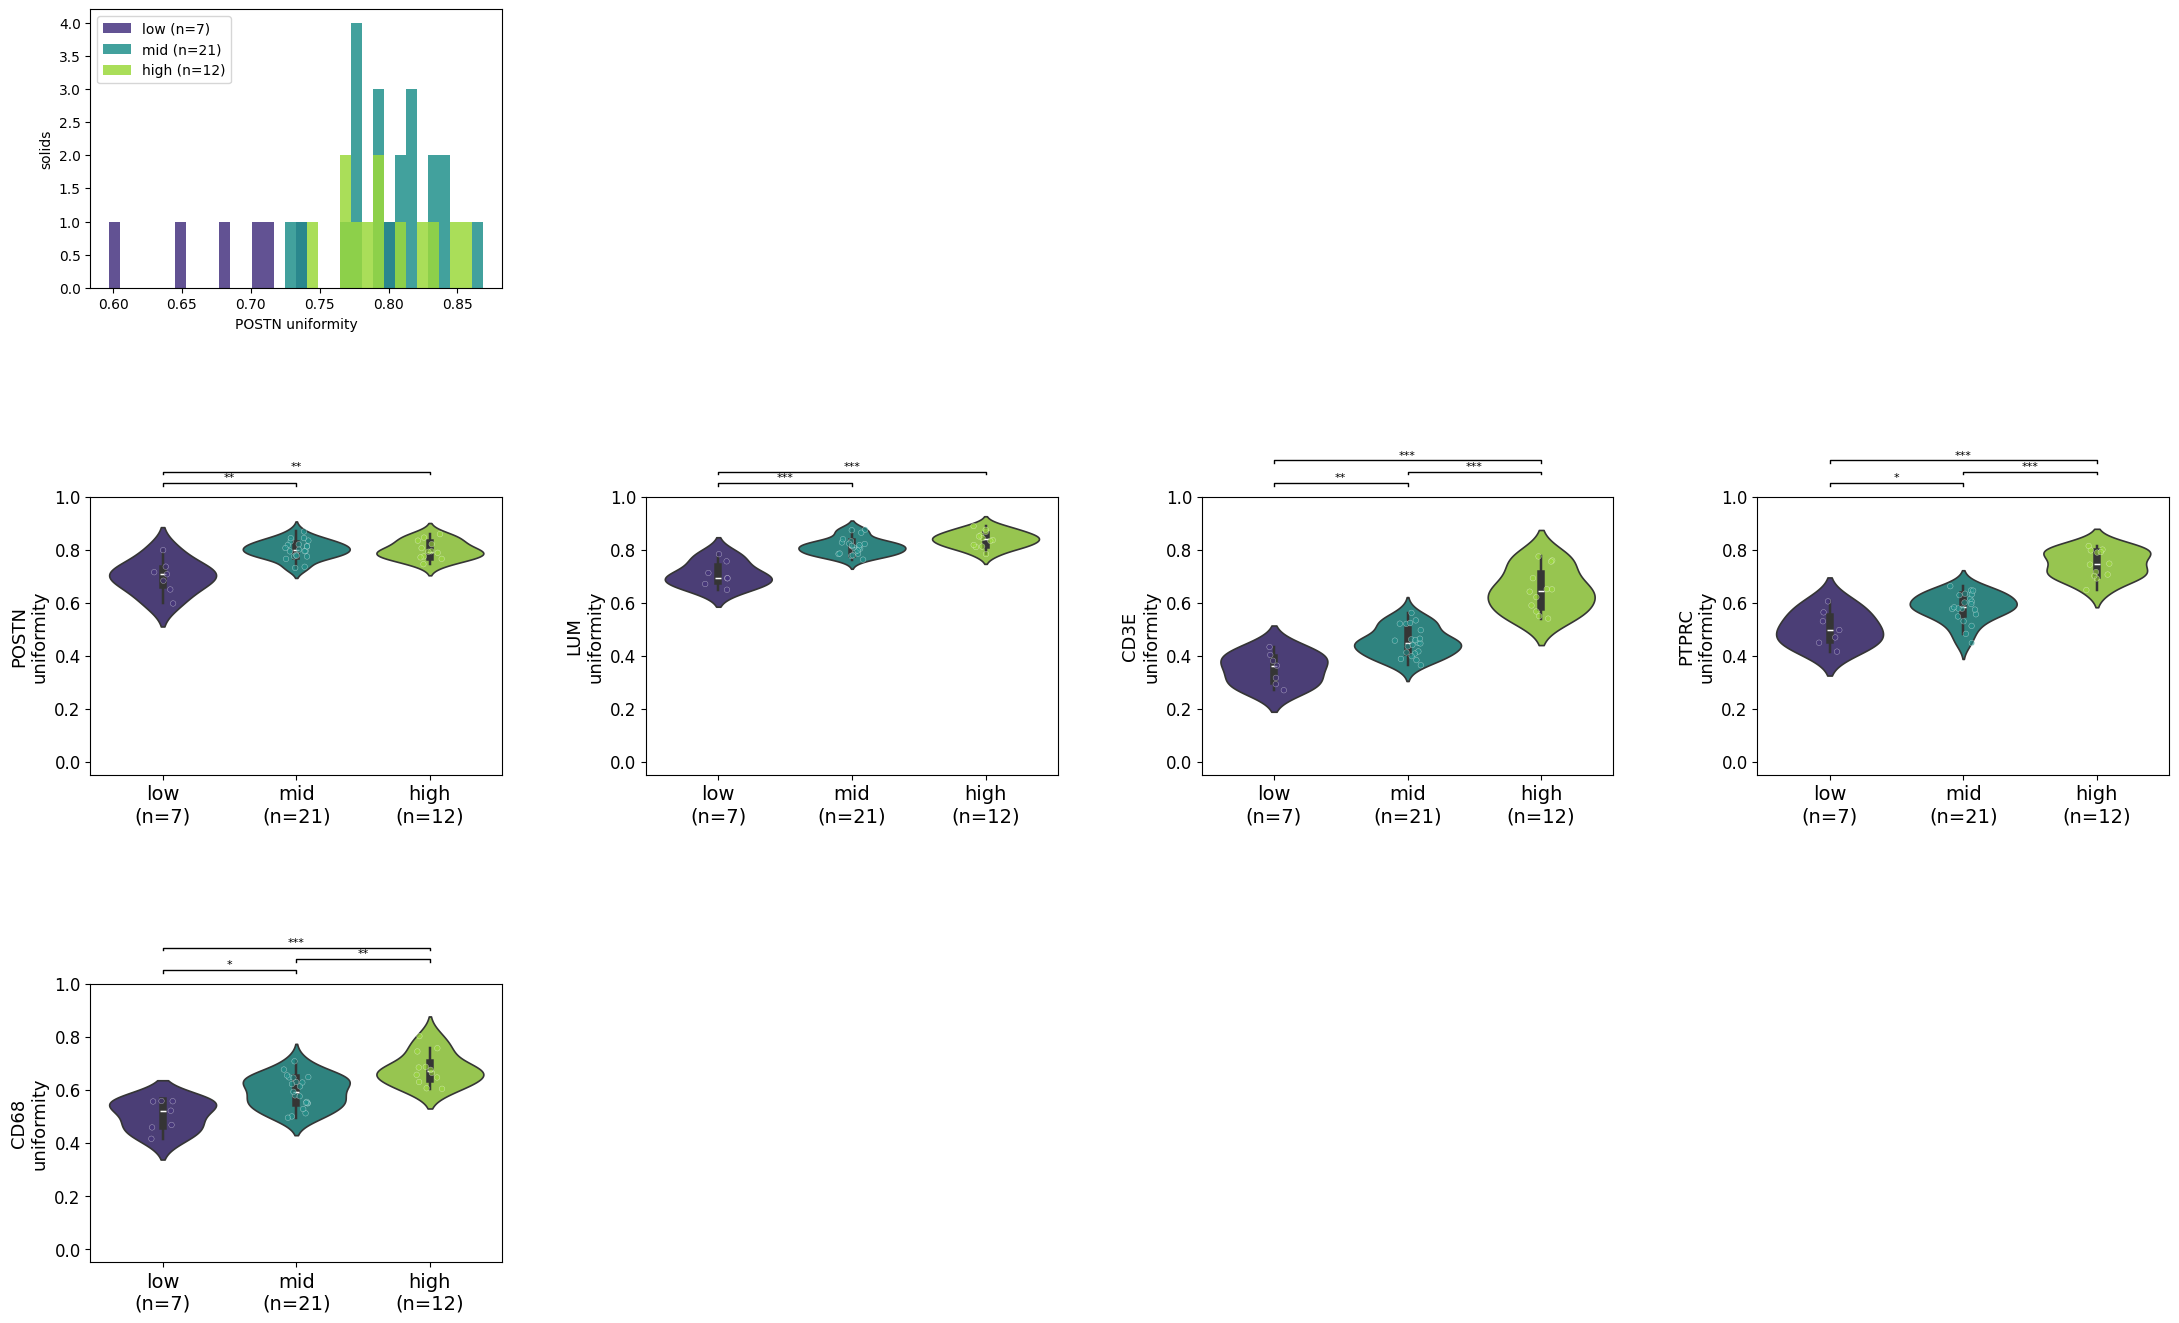

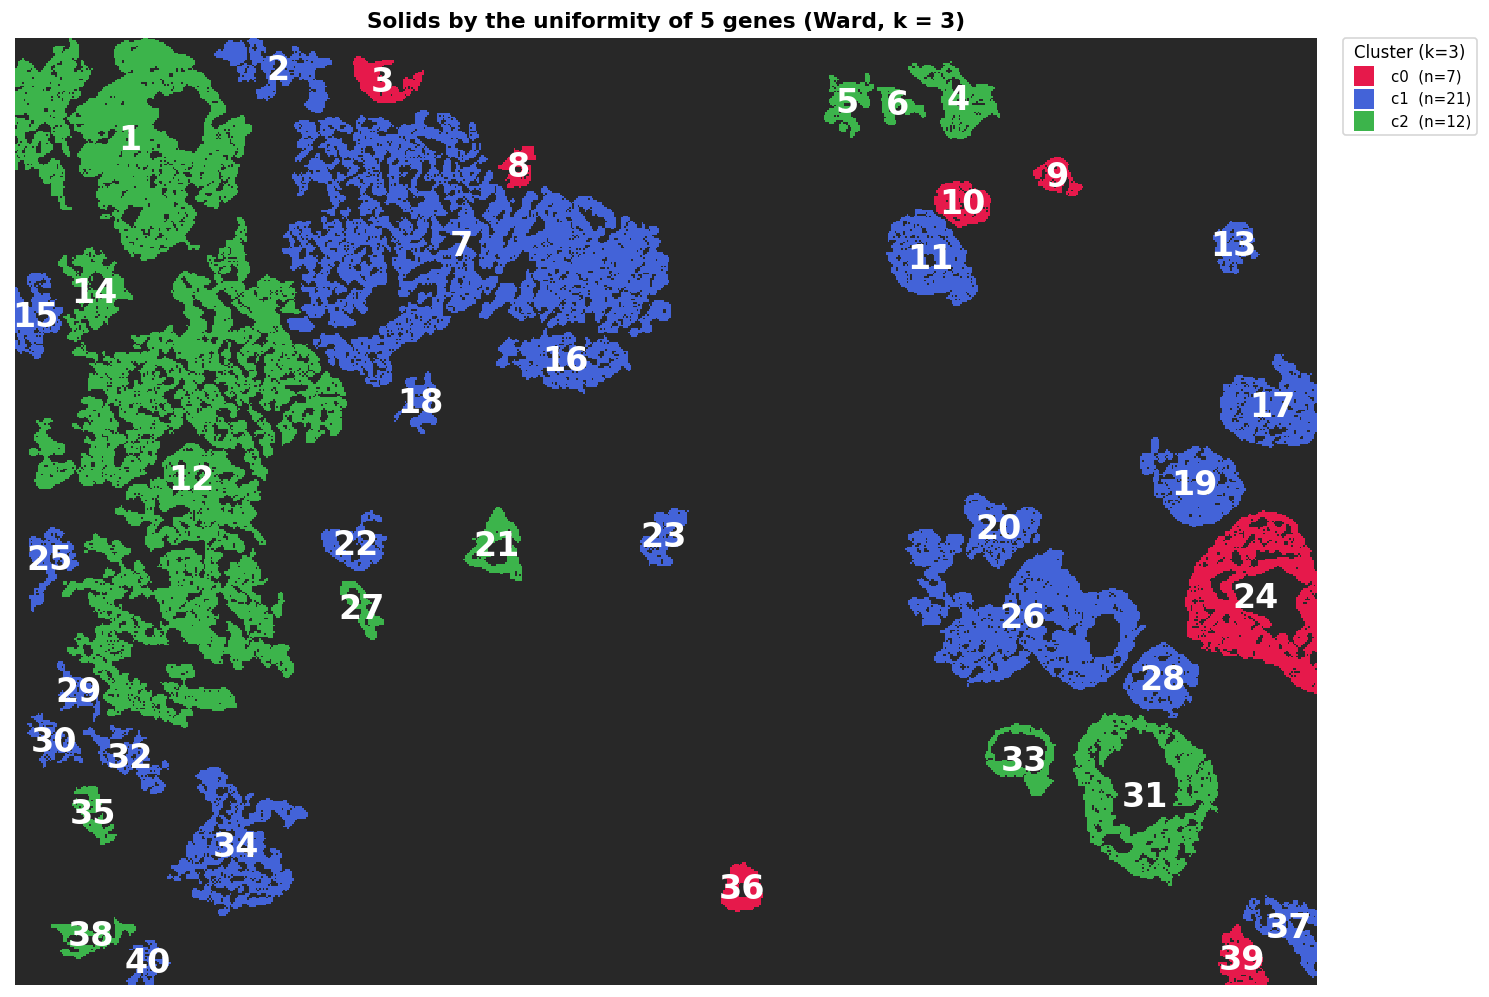

In [6]:
GENES = ["POSTN", "LUM", "CD3E", "PTPRC", "CD68"]
gene_u = scomv.solid_gene_uniformity(grid, solid, GENES)
multi = scomv.cluster_solids(gene_u, method="ward", n_clusters=3, order_by="CD3E")
scomv.plot_solid_clusters(multi)
plt.show()
plot_cluster_map(labels_img, solid.obs, multi.cluster_of_solid, n_clusters=multi.k,
                 title="Solids by the uniformity of 5 genes (Ward, k = 3)")
plt.show()

The cell-type version is in the solid_cell_clustering tutorial; both tables can be joined
(`gene_u.join(cell_u)`) and clustered together.